In [7]:
import math 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.signal import iirnotch, sosfilt, tf2sos
from scipy.ndimage import gaussian_filter1d

from plot_helpers import plot_signal, plot_emg_vs_joystick, plot_frequencies

In [59]:
def notch_cascade_sos(fs, base=50.0, q=30.0):
    """Cascada de notches en base, 2*base, 3*base, ... < Nyquist*0.95.
    Mismo diseno que monitor.py."""
    nyq = fs / 2
    sections = []
    f = base
    while f < nyq * 0.95:
        b, a = iirnotch(f, q, fs=fs)
        sections.append(tf2sos(b, a))
        f += base
    return np.vstack(sections) if sections else None

def causal_notch(x, sos):
    if sos is None:
        return np.asarray(x)
    return sosfilt(sos, np.asarray(x))

def causal_bandpass(x, fs, low=70, high=233, order=4):
    b, a = signal.butter(order, [low, high], btype="bandpass", fs=fs)
    return signal.lfilter(b, a, x)

def rolling_rms(x, fs, window_ms=50):
    w = max(1, int(fs * window_ms / 1000))
    x2 = np.asarray(x) ** 2
    kernel = np.ones(w) / w
    return np.sqrt(np.convolve(x2, kernel, mode="same"))

def preprocess_emg_rms(df, fs, ext_col, flex_col, prefix, window_ms=50,
                       notch_base=50.0, notch_q=30.0):
    """Pipeline RMS para un dedo. prefix es 'ind' o 'med'; produce columnas
    {prefix}_ext_bp, {prefix}_flex_bp, {prefix}_ext_rms, {prefix}_flex_rms."""
    df = df.copy()
    if notch_base > 0:
        sos = notch_cascade_sos(fs, notch_base, notch_q)
    else:
        sos = None

    df[f"{prefix}_ext_bp"]  = causal_bandpass(causal_notch(df[ext_col].values,  sos), fs)
    df[f"{prefix}_flex_bp"] = causal_bandpass(causal_notch(df[flex_col].values, sos), fs)

    df[f"{prefix}_ext_rms"]  = rolling_rms(df[f"{prefix}_ext_bp"].values,  fs, window_ms)
    df[f"{prefix}_flex_rms"] = rolling_rms(df[f"{prefix}_flex_bp"].values, fs, window_ms)
    return df

def preprocess_emg_butter(df, fs, ext_col, flex_col, prefix, low_pass_hz=1,
                          notch_base=50.0, notch_q=30.0):
    """Pipeline envelope (butter LP) para un dedo. Produce columnas
    {prefix}_ext_env, {prefix}_flex_env."""
    df = df.copy()
    if notch_base > 0:
        sos = notch_cascade_sos(fs, notch_base, notch_q)
    else:
        sos = None

    df[f"{prefix}_ext_bp"]  = causal_bandpass(causal_notch(df[ext_col].values,  sos), fs)
    df[f"{prefix}_flex_bp"] = causal_bandpass(causal_notch(df[flex_col].values, sos), fs)

    df[f"{prefix}_ext_rect"]  = np.abs(df[f"{prefix}_ext_bp"])
    df[f"{prefix}_flex_rect"] = np.abs(df[f"{prefix}_flex_bp"])

    b_lp, a_lp = signal.butter(2, low_pass_hz, btype="lowpass", fs=fs)
    df[f"{prefix}_ext_env"]  = signal.filtfilt(b_lp, a_lp, df[f"{prefix}_ext_rect"])
    df[f"{prefix}_flex_env"] = signal.filtfilt(b_lp, a_lp, df[f"{prefix}_flex_rect"])
    return df

def smooth_signal(x, fs, lp_hz=5):
    b, a = signal.butter(2, lp_hz, btype="lowpass", fs=fs)
    return signal.filtfilt(b, a, x)

def gaussian_smooth_target(x, fs, sigma_ms=150):
    sigma_samples = sigma_ms / 1000 * fs
    return gaussian_filter1d(
        x.astype(float),
        sigma=sigma_samples,
        mode="nearest"
    )

def standardize(x):
    return (x - x.mean()) / x.std()

def standardize_median_mad(x, exclude_mask=None):
      """Z-normaliza un canal usando median + MAD*1.4826 (robusto a outliers).

      Args:
          x: array 1D [T].
          exclude_mask: bool array [T], True para samples a INCLUIR en stats.
                        Si None, usa todos.

      Returns:
          normalized: array [T] normalizado
          center:     float (median)
          scale:      float (MAD*1.4826 + eps)
      """
      used = x if exclude_mask is None else x[exclude_mask]
      center = float(np.median(used))
      mad = float(np.median(np.abs(used - center)))
      scale = mad * 1.4826 + 1e-6
      normalized = ((x - center) / scale).astype(np.float32)
      return normalized
    
def combine_joy(df, ext_col, flex_col, fs, sigma_ms=50, reflect=False):
    """Mismo patron del notebook original: signo invertido + centrado a la
    mediana, gaussian smooth, suma de los dos ejes -> 1 senal de posicion."""
    mult = 1
    if reflect:
        mult = -1
    y_top    = gaussian_smooth_target(mult*(df[ext_col].values  - np.mean(df[ext_col])),  fs, sigma_ms)
    y_bottom = gaussian_smooth_target(mult*(df[flex_col].values - np.mean(df[flex_col])), fs, sigma_ms)
    return y_top, y_bottom, y_top + y_bottom

In [60]:
CSV_PATH  = "./data/raw/P01/P01_S07_20260620_120736.csv"
USE_NOTCH = False   # True = aplicar cascada notch (50/100/...) en preprocess

df = pd.read_csv(CSV_PATH)

df["t"] = df["t_micros"] * 1e-6

# Centrado de los 4 EMG
for col in ["emg0", "emg1", "emg2", "emg3"]:
    df[col] -= df[col].mean()

dt = np.diff(df["t"])
fs = 1 / np.mean(dt)
print(f"Sampling frequency: {fs:.1f} Hz")
print(f"Sampling std: {dt.std()*1e6:.1f} us")

# Combinar los 2 ejes de cada joystick en una sola senal de posicion por dedo.
df["y_top_ind"], df["y_bot_ind"], df["joy_ind"] = combine_joy(
    df, "joy_ext_ind", "joy_flex_ind", fs, sigma_ms=50, reflect=True)
df["y_top_med"], df["y_bot_med"], df["joy_med"] = combine_joy(
    df, "joy_ext_med", "joy_flex_med", fs, sigma_ms=50)

df.dropna(inplace=True)
print(f"N samples: {len(df)}")
df.head()

Sampling frequency: 560.1 Hz
Sampling std: 136340.9 us
N samples: 1082031


,pc_timestamp,t_micros,emg0,emg1,emg2,emg3,joy_ext_ind,joy_flex_ind,joy_ext_med,joy_flex_med,...,subject_id,placement_id,optional_notes,t,y_top_ind,y_bot_ind,joy_ind,y_top_med,y_bot_med,joy_med
0,1.781968e+09,2422498151,-200421.831385,-164235.700735,-34726.304634,-55871.715541,1874.0,1909.0,1907.0,1887.0,...,P01,P01-D,S07 placement D,2422.498151,-351.236991,348.949288,-2.287704,-379.411666,338.579489,-40.832177
1,1.781968e+09,2422499724,-165301.831385,-149465.700735,-17280.304634,-54928.715541,1876.0,1910.0,1863.0,1839.0,...,P01,P01-D,S07 placement D,2422.499724,-351.288718,348.957230,-2.331488,-379.731924,338.052923,-41.679001
2,1.781968e+09,2422501293,-162293.831385,-152199.700735,-18640.304634,-62192.715541,1885.0,1897.0,1899.0,1853.0,...,P01,P01-D,S07 placement D,2422.501293,-351.340319,348.965461,-2.374858,-380.051133,337.526577,-42.524556
3,1.781968e+09,2422502868,-272704.831385,-161226.700735,6973.695366,-57638.715541,1883.0,1916.0,1879.0,1848.0,...,P01,P01-D,S07 placement D,2422.502868,-351.391514,348.973818,-2.417696,-380.368883,337.001083,-43.367800
4,1.781968e+09,2422504438,-277161.831385,-155661.700735,46426.695366,-55369.715541,1871.0,1911.0,1863.0,1835.0,...,P01,P01-D,S07 placement D,2422.504438,-351.442199,348.982135,-2.460065,-380.684790,336.476964,-44.207826


In [61]:
notch_base = 50.0 if USE_NOTCH else 0.0
df = df[~df["task"].isin(["noise_wrist_grip", "transition"])].reset_index(drop=True)

# INDICE
df = preprocess_emg_rms   (df, fs, ext_col="emg0", flex_col="emg1", prefix="ind",
                           window_ms=300, notch_base=notch_base)
df = preprocess_emg_butter(df, fs, ext_col="emg0", flex_col="emg1", prefix="ind",
                           low_pass_hz=1, notch_base=notch_base)

df["activity_ind"] = standardize_median_mad(df["ind_ext_rms"]) - standardize_median_mad(df["ind_flex_rms"])

# MEDIO
df = preprocess_emg_rms   (df, fs, ext_col="emg2", flex_col="emg3", prefix="med",
                           window_ms=300, notch_base=notch_base)
df = preprocess_emg_butter(df, fs, ext_col="emg2", flex_col="emg3", prefix="med",
                           low_pass_hz=1, notch_base=notch_base)

df["activity_med"] = standardize_median_mad(df["med_ext_rms"]) - standardize_median_mad(df["med_flex_rms"])

# Tirar primeros 300 samples (transient del bandpass causal) y ultimos 100
df = df.iloc[0:-100].reset_index(drop=True)

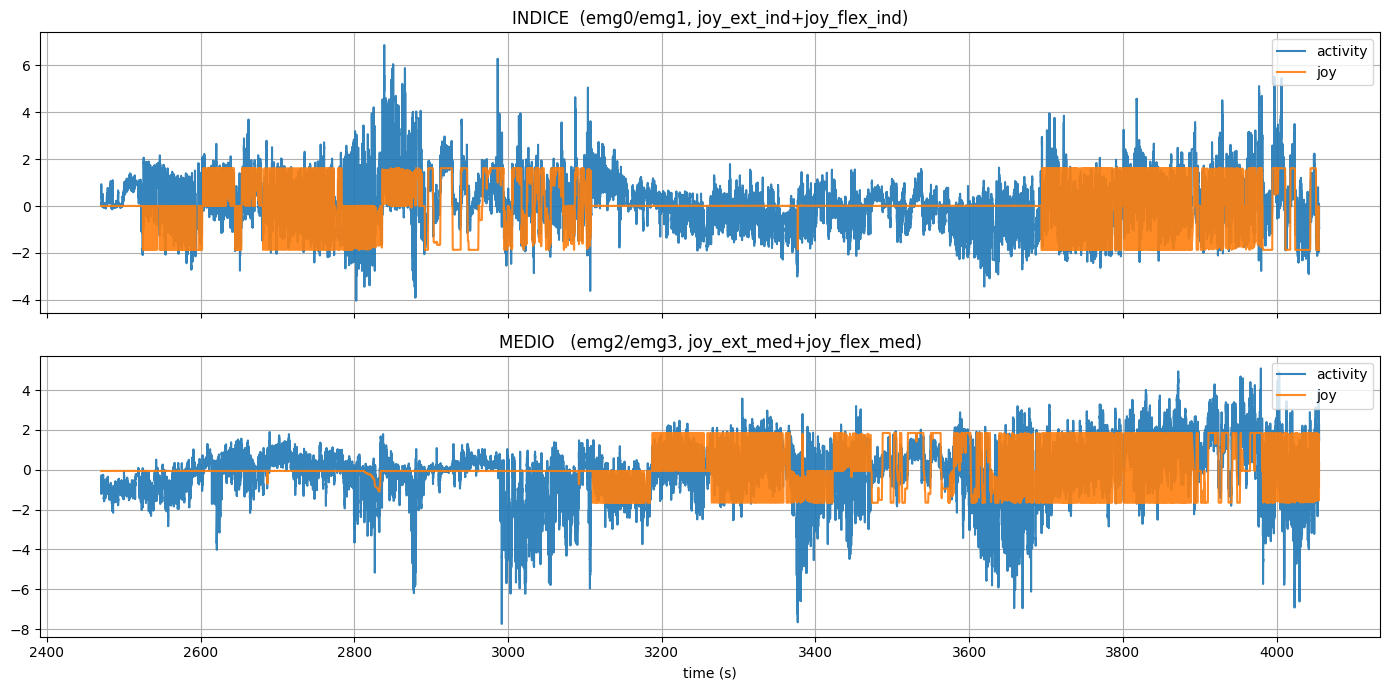

In [64]:
# Activity (ext - flex normalizados) vs posicion combinada del joystick.
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(df["t"], df["activity_ind"], label="activity", alpha=0.9)
axes[0].plot(df["t"], standardize(df["joy_ind"]),      label="joy",      alpha=0.9)
axes[0].set_title("INDICE  (emg0/emg1, joy_ext_ind+joy_flex_ind)")
axes[0].grid(True); axes[0].legend(loc="upper right")

axes[1].plot(df["t"], df["activity_med"], label="activity", alpha=0.9)
axes[1].plot(df["t"], standardize(df["joy_med"]),      label="joy",      alpha=0.9)
axes[1].set_title("MEDIO   (emg2/emg3, joy_ext_med+joy_flex_med)")
axes[1].set_xlabel("time (s)")
axes[1].grid(True); axes[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

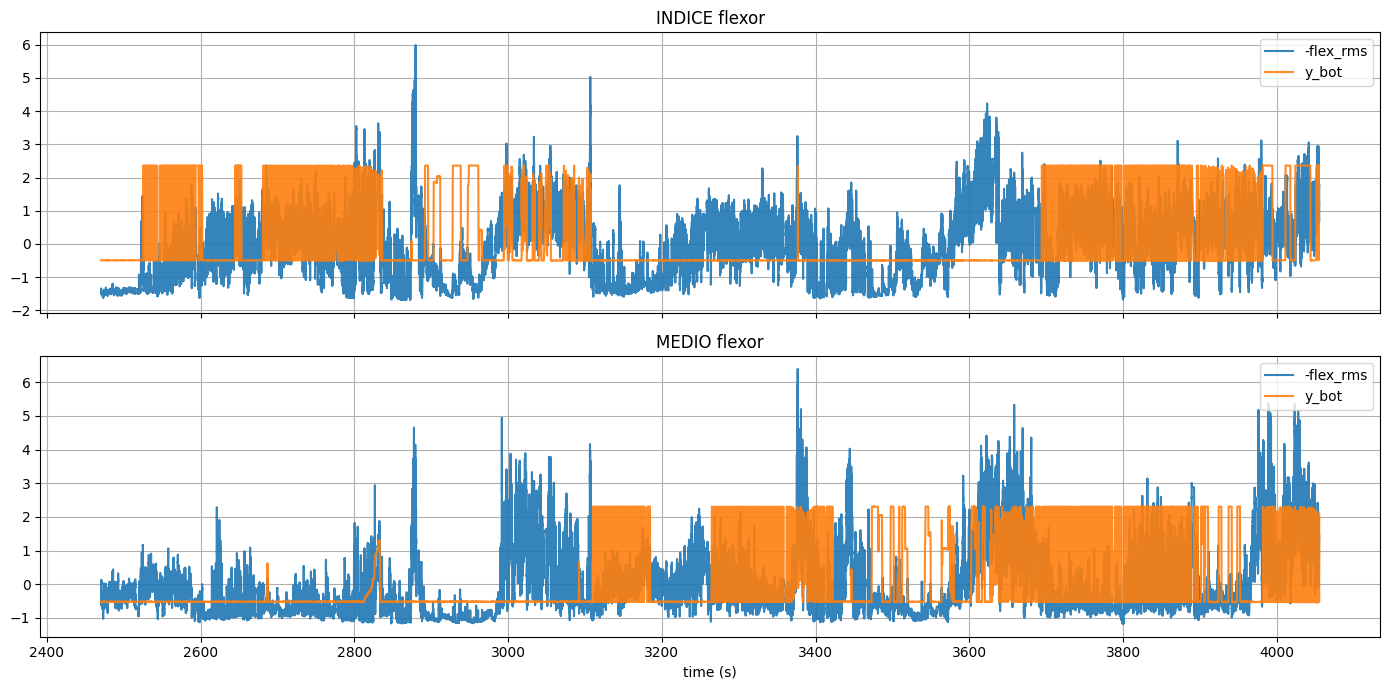

In [52]:
# Flexor RMS vs eje "bottom" del joystick por dedo.
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(df["t"], standardize(df["ind_flex_rms"]), label="-flex_rms", alpha=0.9)
axes[0].plot(df["t"], -standardize(df["y_bot_ind"]),    label="y_bot",     alpha=0.9)
axes[0].set_title("INDICE flexor")
axes[0].grid(True); axes[0].legend(loc="upper right")

axes[1].plot(df["t"], standardize(df["med_flex_rms"]), label="-flex_rms", alpha=0.9)
axes[1].plot(df["t"], -standardize(df["y_bot_med"]),    label="y_bot",     alpha=0.9)
axes[1].set_title("MEDIO flexor")
axes[1].set_xlabel("time (s)")
axes[1].grid(True); axes[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

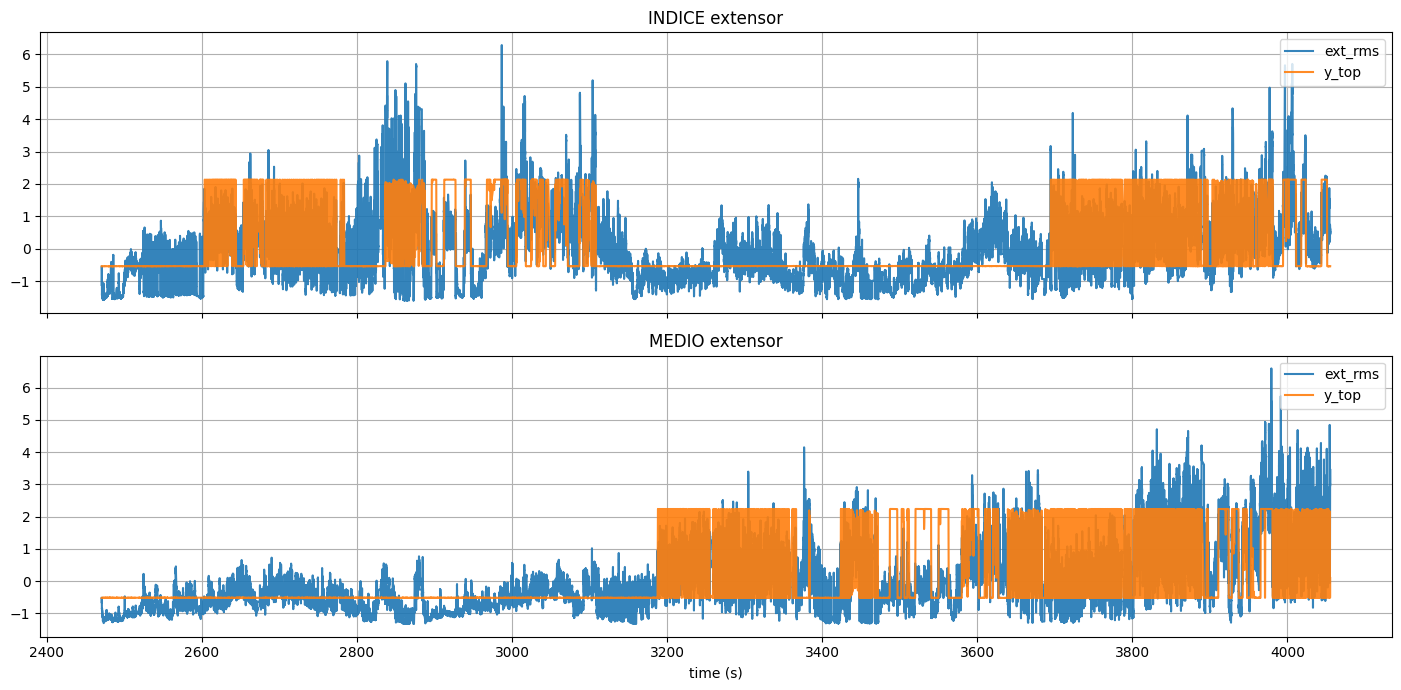

In [41]:
# Extensor RMS vs eje "top" del joystick por dedo.
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(df["t"], standardize(df["ind_ext_rms"]), label="ext_rms", alpha=0.9)
axes[0].plot(df["t"], standardize(df["y_top_ind"]),   label="y_top",   alpha=0.9)
axes[0].set_title("INDICE extensor")
axes[0].grid(True); axes[0].legend(loc="upper right")

axes[1].plot(df["t"], standardize(df["med_ext_rms"]), label="ext_rms", alpha=0.9)
axes[1].plot(df["t"], standardize(df["y_top_med"]),   label="y_top",   alpha=0.9)
axes[1].set_title("MEDIO extensor")
axes[1].set_xlabel("time (s)")
axes[1].grid(True); axes[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

In [16]:
# =========================================================================
# Diagnostico por task: activity_ind vs activity_med
# =========================================================================
# Necesita la columna "task" (CSVs de collect.py la traen; capture_raw NO).

assert "task" in df.columns, "df no tiene columna 'task' - usa un CSV de collect.py"

QUIET = {
    "rest_baseline":         "both",
    "slow_cycles_ind":       "med", "fast_flex_ind":         "med",
    "fast_ext_ind":          "med", "holds_intermediate_ind":"med",
    "microcorrections_ind":  "med", "free_controlled_ind":   "med",
    "slow_cycles_med":       "ind", "fast_flex_med":         "ind",
    "fast_ext_med":          "ind", "holds_intermediate_med":"ind",
    "microcorrections_med":  "ind", "free_controlled_med":   "ind",
    "ind_move_med_hold":     "med", "med_move_ind_hold":     "ind",
    "both_cycles_inphase":   None,  "both_cycles_antiphase": None,
    "both_free":             None,
    "noise_other_fingers":   "both","noise_wrist_grip":      "both",
}

# Tabla resumen: std de activity por task.
rows = []
for task, sub in df.groupby("task"):
    if task == "transition":
        continue
    rows.append({
        "task":         task,
        "n_samples":    len(sub),
        "std_act_ind":  sub["activity_ind"].std(),
        "std_act_med":  sub["activity_med"].std(),
        "quiet":        QUIET.get(task, "?"),
    })
summary = pd.DataFrame(rows).sort_values("task").reset_index(drop=True)
print("Stats por task:")
print(summary.to_string(index=False))

Stats por task:
                  task  n_samples  std_act_ind  std_act_med quiet
 both_cycles_antiphase      63746     0.755830     0.828918  None
   both_cycles_inphase      63745     0.884593     0.776910  None
          fast_ext_ind      31875     1.357923     0.721733   med
          fast_ext_med      31871     0.496380     0.770281   ind
         fast_flex_ind      31881     1.078367     0.582552   med
         fast_flex_med      31876     0.613381     1.016732   ind
   free_controlled_ind      31880     0.659968     0.835740   med
   free_controlled_med      31879     0.582902     1.165255   ind
holds_intermediate_ind      57375     0.832131     0.292990   med
holds_intermediate_med      57377     0.436616     0.475867   ind
     ind_move_med_hold      50995     0.842391     1.007691   med
     med_move_ind_hold      50996     1.111894     1.113111   ind
  microcorrections_ind      44624     0.833308     0.967889   med
  microcorrections_med      44629     0.486688     0.845320 

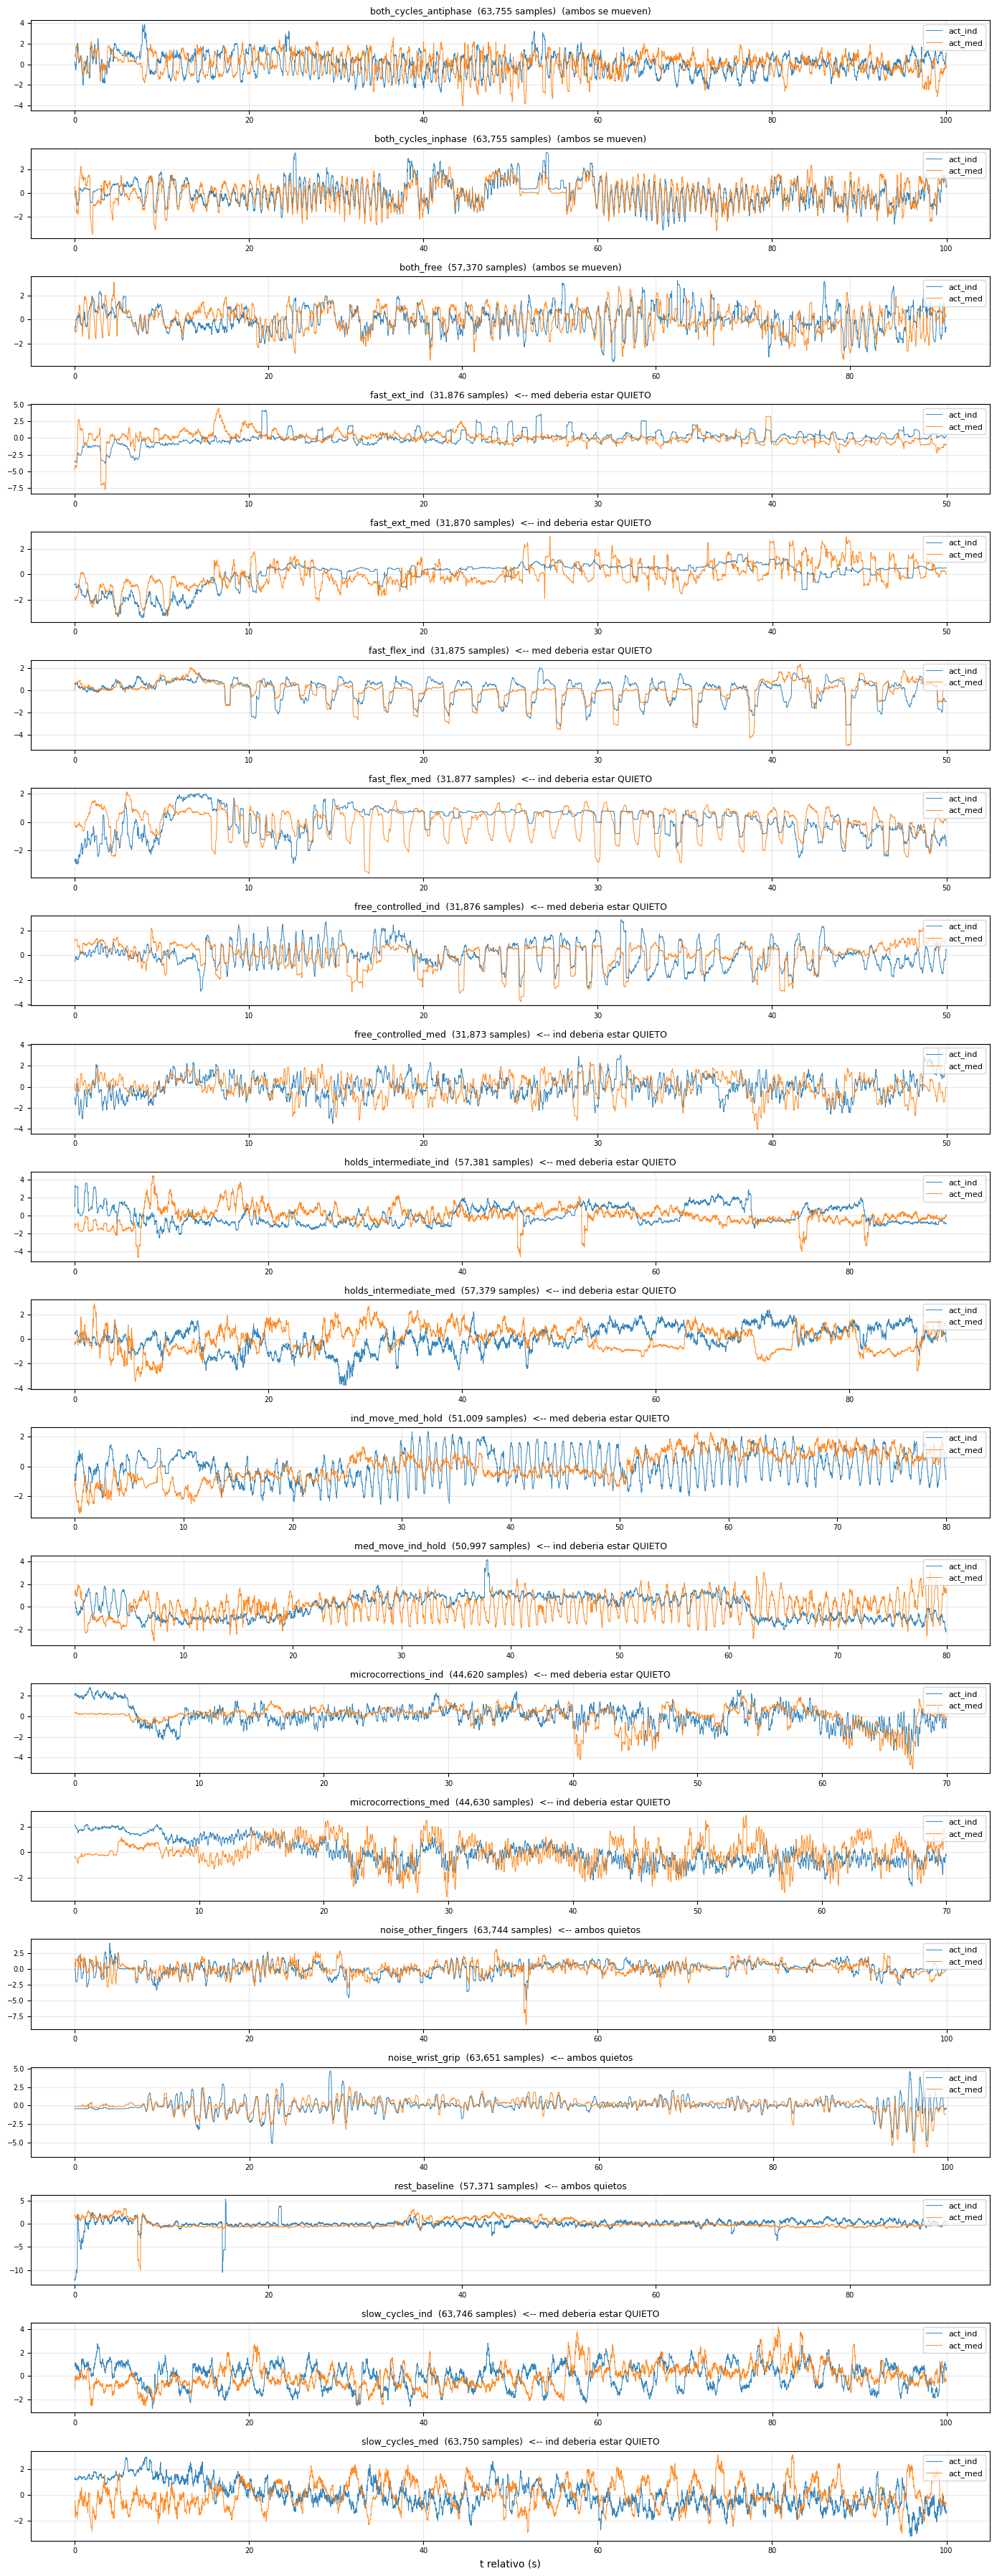

In [9]:
# Grid: 1 fila por task. Cada panel muestra activity_ind y activity_med
# normalizados, con anotacion de que dedo "deberia" estar quieto.

tasks_to_plot = [t for t in summary["task"] if t in QUIET]
n_rows = len(tasks_to_plot)
fig, axes = plt.subplots(n_rows, 1, figsize=(14, 1.8 * n_rows), sharex=False)
if n_rows == 1:
    axes = [axes]

for ax, task in zip(axes, tasks_to_plot):
    sub = df[df["task"] == task]
    t_rel = sub["t"].values - sub["t"].iloc[0]
    ax.plot(t_rel, standardize(sub["activity_ind"]), label="act_ind",
            color="tab:blue", lw=0.7, alpha=0.9)
    ax.plot(t_rel, standardize(sub["activity_med"]), label="act_med",
            color="tab:orange", lw=0.7, alpha=0.9)

    q = QUIET.get(task)
    flag = {
        "ind":  "<-- ind deberia estar QUIETO",
        "med":  "<-- med deberia estar QUIETO",
        "both": "<-- ambos quietos",
        None:   "(ambos se mueven)",
    }[q]
    ax.set_title(f"{task}  ({len(sub):,} samples)  {flag}", fontsize=9)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
    ax.tick_params(labelsize=7)

axes[-1].set_xlabel("t relativo (s)")
plt.tight_layout()
plt.show()